# Predicao de Risco de AVC (Stroke): Modelagem, Avaliacao e Explicabilidade

**Projeto de Machine Learning - APS 2**

**Docente:** Humberto Sandman

**Equipe:**

Emily Britto - *emilybg@al.insper.edu.br*

Gabriel Chaves Aguiar - *gabrielca5@al.insper.edu.br*

**Data de entrega:** 30/10/2026

**Referencias bibliograficas:** ver Secao 5, ao final deste notebook.

---

Continuacao da APS1 (`aps_machine_learning.ipynb`), onde fizemos a analise
exploratoria do dataset de AVC e construimos o pipeline de pre-processamento.
Aqui partimos direto para a modelagem: selecao de modelos, ajuste de
hiperparametros, avaliacao no conjunto de teste e interpretacao.

Para o notebook rodar de ponta a ponta e preciso o SHAP, que ainda nao esta nas
dependencias do projeto. No terminal, na raiz do repositorio:

```
uv add shap
```

## Setup: o pipeline da APS1

Repetimos aqui o carregamento, a divisao treino/teste e o pre-processador
construidos na APS1, sem alteracoes, para que este notebook seja autocontido.
A divisao usa `stratify=y` e o mesmo `random_state=42`, entao o conjunto de
teste e exatamente o mesmo da APS1.

In [1]:
import warnings
warnings.filterwarnings("ignore")


import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

path = kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset")
df = pd.read_csv(f"{path}/healthcare-dataset-stroke-data.csv")

X = df.drop(columns=["stroke", "id"])
y = df["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

colunas_numericas = ["age", "avg_glucose_level", "bmi"]
colunas_categoricas = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status",
]
colunas_binarias = ["hypertension", "heart_disease"]


def constroi_pre_processador(add_indicator: bool = False) -> ColumnTransformer:
    """Pre-processador da APS1.

    O parametro add_indicator fica desligado por padrao: ele so sera usado na
    secao 1.3, quando propusermos a mudanca no pipeline.
    """
    pipeline_numerico = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median", add_indicator=add_indicator)),
            ("scaler", StandardScaler()),
        ]
    )

    pipeline_categorico = Pipeline(
        [("one_hot", OneHotEncoder(handle_unknown="ignore"))]
    )

    return ColumnTransformer(
        transformers=[
            ("numericas", pipeline_numerico, colunas_numericas),
            ("categoricas", pipeline_categorico, colunas_categoricas),
            ("binarias", "passthrough", colunas_binarias),
        ]
    )


pre_processador = constroi_pre_processador()

print(f"Treino: {X_train.shape[0]} observacoes | Teste: {X_test.shape[0]} observacoes")
print(f"Prevalencia de AVC no treino: {y_train.mean() * 100:.2f}%")

Treino: 4088 observacoes | Teste: 1022 observacoes
Prevalencia de AVC no treino: 4.87%


## Escolha da metrica de desempenho

Escolhemos a **PR-AUC** (*average precision*) como metrica principal.

A justificativa vem direto do que encontramos na APS1: apenas **4,87%** dos
pacientes tiveram AVC. Nesse cenario:

- **Accuracy e inutil.** Um modelo que responde "sem AVC" para todo mundo acerta
  95,1% das vezes e nao detecta um unico caso.
- **ROC-AUC e otimista.** A taxa de falsos positivos tem como denominador a
  classe majoritaria, que e enorme; centenas de falsos positivos mal mexem no
  eixo x da curva ROC. O valor fica alto mesmo quando a classe positiva esta
  sendo prevista mal.
- **PR-AUC enxerga o problema.** Precision e recall ignoram os verdadeiros
  negativos, que sao justamente a massa que nao nos interessa. A linha de base
  da PR-AUC e a propria prevalencia (**0,0487**), entao qualquer valor acima
  disso e ganho real sobre o acaso, e a comparacao fica interpretavel.

Usamos a PR-AUC em **todas** as etapas: comparacao dos modelos base, `scoring`
dos GridSearchCV, avaliacao da mudanca no pipeline e curvas de aprendizado.
A estrategia de validacao e sempre `StratifiedKFold(n_splits=5, shuffle=True)`,
estratificada pelo mesmo motivo que estratificamos a divisao treino/teste: com
4,87% de positivos, um fold poderia facilmente ficar sem casos suficientes.

Na secao 2 reportamos tambem Accuracy, Precision, Recall, F1 e ROC-AUC, como
pede o enunciado, mas a escolha do melhor modelo foi feita pela PR-AUC.

In [2]:
from sklearn.model_selection import cross_val_score

METRICA = "average_precision"  # PR-AUC
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f"Linha de base da PR-AUC (prevalencia): {y_train.mean():.4f}")

Linha de base da PR-AUC (prevalencia): 0.0487


---

## 1. Selecao e implementacao dos modelos

### 1.1 Os tres modelos

| Modelo | Papel | Por que este |
|---|---|---|
| `DummyClassifier` | Piso de referencia | Prediz respeitando a proporcao das classes, sem olhar para as features. Qualquer modelo util precisa superar isso. |
| `LogisticRegression` | Linear com regularizacao | Era o modelo da APS1. A regularizacao (L1/L2) controla o overfitting e, no caso do L1, zera coeficientes irrelevantes. |
| `RandomForestClassifier` | Ensemble de arvores | Captura interacoes e relacoes nao lineares que a regressao logistica nao alcanca, sem precisar que a gente as declare. |

Os tres entram no **mesmo pipeline**, com o pre-processador da APS1 na frente.
Isso garante que a imputacao e a padronizacao sejam aprendidas apenas no fold de
treino de cada particao da validacao cruzada, sem vazamento.

Tanto a regressao logistica quanto a floresta usam `class_weight="balanced"`,
que foi a nossa resposta ao desbalanceamento ja na APS1: o peso de cada classe
fica inversamente proporcional a sua frequencia, entao errar um caso de AVC
custa cerca de 20 vezes mais do que errar um caso negativo.

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

modelos = {
    "Dummy": DummyClassifier(strategy="stratified", random_state=42),
    "Regressao Logistica": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        class_weight="balanced", random_state=42, n_jobs=-1
    ),
}

# Cada modelo passa pelo mesmo pipeline de pre-processamento da APS1,
# isolando o efeito da escolha do classificador.
resultados_base = []

for nome, classificador in modelos.items():
    pipeline = Pipeline(
        [
            ("pre_processamento", constroi_pre_processador()),
            ("classificador", classificador),
        ]
    )

    scores = cross_val_score(
        pipeline, X_train, y_train, scoring=METRICA, cv=cv, n_jobs=-1
    )

    resultados_base.append(
        {
            "modelo": nome,
            "PR-AUC (media)": scores.mean(),
            "desvio padrao": scores.std(),
        }
    )

tabela_base = pd.DataFrame(resultados_base).set_index("modelo").round(4)

display(tabela_base)

,PR-AUC (media),desvio padrao
modelo,,
Dummy,0.0488,0.0004
Regressao Logistica,0.1933,0.0389
Random Forest,0.1691,0.0393


**Leitura.** O Dummy fica em ~0,049, exatamente a prevalencia, como esperado:
e a confirmacao de que a metrica esta calibrada. Os dois modelos reais ficam em
torno de 0,17 a 0,19, ou seja, cerca de **4x acima do acaso**. A regressao
logistica sai na frente da floresta na configuracao padrao, o que faz sentido:
uma floresta sem limite de profundidade decora o treino, e com 249 casos
positivos ha pouquissimo sinal para decorar.

O desvio padrao entre os folds (~0,04) e alto em relacao a media. Isso tambem e
efeito do desbalanceamento: cada fold de validacao tem apenas ~50 casos
positivos, entao a estimativa oscila bastante. E um motivo a mais para nao
celebrar diferencas pequenas entre modelos.

### 1.2 Selecao de hiperparametros

Usamos `GridSearchCV` com a mesma metrica e a mesma estrategia de validacao. As
grades foram escolhidas em torno do que costuma importar em cada familia:

- **Regressao logistica:** `C` (forca da regularizacao, em escala log de 0,001 a
  100) e `penalty` (L1 vs L2). O solver `liblinear` foi escolhido por suportar
  as duas penalidades.
- **Random Forest:** os parametros que controlam o quanto a floresta pode
  decorar - `max_depth`, `min_samples_leaf` e `max_features`. Fixamos
  `n_estimators=300`, porque mais arvores nunca pioram o resultado de uma
  floresta, so custam tempo.

In [4]:
from sklearn.model_selection import GridSearchCV

# Grade centrada no que mais afeta um modelo linear: forca de
# regularizacao (C) e tipo de penalidade (L1 zera coeficientes, L2 so encolhe).
grade_logistica = {
    "classificador__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "classificador__penalty": ["l1", "l2"],
    "classificador__solver": ["liblinear"],
}

busca_logistica = GridSearchCV(
    Pipeline(
        [
            ("pre_processamento", constroi_pre_processador()),
            (
                "classificador",
                LogisticRegression(
                    class_weight="balanced", max_iter=1000, random_state=42
                ),
            ),
        ]
    ),
    grade_logistica,
    scoring=METRICA,
    cv=cv,
    n_jobs=-1,
)

busca_logistica.fit(X_train, y_train)

print("Regressao Logistica")
print(f"  Melhor PR-AUC: {busca_logistica.best_score_:.4f}")
print(f"  Melhores parametros: {busca_logistica.best_params_}")

Regressao Logistica
  Melhor PR-AUC: 0.1935
  Melhores parametros: {'classificador__C': 1, 'classificador__penalty': 'l1', 'classificador__solver': 'liblinear'}


In [5]:
# n_estimators fica fixo; os demais parametros controlam o quanto a
# floresta pode decorar o treino (profundidade, folha minima, features por split).
grade_floresta = {
    "classificador__n_estimators": [300],
    "classificador__max_depth": [None, 5, 10],
    "classificador__min_samples_leaf": [1, 5, 20],
    "classificador__max_features": ["sqrt", 0.5],
}

busca_floresta = GridSearchCV(
    Pipeline(
        [
            ("pre_processamento", constroi_pre_processador()),
            (
                "classificador",
                RandomForestClassifier(
                    class_weight="balanced", random_state=42, n_jobs=-1
                ),
            ),
        ]
    ),
    grade_floresta,
    scoring=METRICA,
    cv=cv,
    n_jobs=-1,
)

busca_floresta.fit(X_train, y_train)

print("Random Forest")
print(f"  Melhor PR-AUC: {busca_floresta.best_score_:.4f}")
print(f"  Melhores parametros: {busca_floresta.best_params_}")

Random Forest
  Melhor PR-AUC: 0.2079
  Melhores parametros: {'classificador__max_depth': 10, 'classificador__max_features': 0.5, 'classificador__min_samples_leaf': 20, 'classificador__n_estimators': 300}


In [6]:
# Compara a PR-AUC antes e depois do GridSearchCV, para isolar o ganho
# que vem apenas do ajuste de hiperparametros.
comparacao = pd.DataFrame(
    {
        "PR-AUC base": [
            tabela_base.loc["Regressao Logistica", "PR-AUC (media)"],
            tabela_base.loc["Random Forest", "PR-AUC (media)"],
        ],
        "PR-AUC ajustado": [busca_logistica.best_score_, busca_floresta.best_score_],
    },
    index=["Regressao Logistica", "Random Forest"],
).round(4)

comparacao["ganho"] = (comparacao["PR-AUC ajustado"] - comparacao["PR-AUC base"]).round(
    4
)

display(comparacao)

,PR-AUC base,PR-AUC ajustado,ganho
Regressao Logistica,0.1933,0.1935,0.0002
Random Forest,0.1691,0.2079,0.0388


**Leitura.** A regressao logistica praticamente nao se move com o ajuste: o
`C=1` escolhido e o proprio valor padrao, e a penalidade L1 so troca umas casas
decimais. Era esperado - o modelo tem poucas features e pouca liberdade para se
ajustar.

A floresta, por outro lado, ganha de forma clara quando a podamos
(`max_depth=10`, `min_samples_leaf=20`) e passa a frente da regressao logistica.
Confirma o diagnostico da secao anterior: a floresta padrao estava decorando, e
limitar o crescimento das arvores resolveu.

O melhor modelo ate aqui e a **Random Forest ajustada**.

### 1.3 Mudanca proposta no pipeline: sinalizar o `bmi` ausente

Na APS1 tratamos os 201 valores ausentes de `bmi` (3,93% da base) imputando a
mediana e seguimos em frente. A imputacao preenche o buraco, mas **apaga a
informacao de que havia um buraco ali**. A pergunta que nao fizemos foi: a
ausencia em si diz alguma coisa?

Diz, e muito.

In [7]:
ausente = df["bmi"].isna()

investigacao = df.groupby(ausente)["stroke"].agg(
    pacientes="count", casos_avc="sum", taxa_avc="mean"
)

investigacao["taxa_avc (%)"] = (investigacao["taxa_avc"] * 100).round(2)
investigacao["idade media"] = df.groupby(ausente)["age"].mean().round(1)
investigacao.index = ["bmi presente", "bmi ausente"]

display(investigacao.drop(columns="taxa_avc"))

,pacientes,casos_avc,taxa_avc (%),idade media
bmi presente,4909,209,4.26,42.9
bmi ausente,201,40,19.90,52.0


**O achado.** Entre os pacientes sem `bmi` registrado, a taxa de AVC e de
**19,90%** - contra **4,26%** entre os que tem a medida. Uma diferenca de quase
**5x**. Esses pacientes tambem sao em media 9 anos mais velhos.

A ausencia nao e aleatoria: ela carrega sinal. A explicacao mais provavel e que
pacientes em estado grave (ou que vieram a obito) nao tiveram o IMC aferido, e
esses sao justamente os mais propensos a ter tido um AVC. Esse padrao, em que a propria ausencia de um valor esta correlacionada com o desfecho, e um caso classico de dado ausente nao aleatorio (MNAR - *missing not at random*) [1]: a ausencia carrega informacao e nao pode ser tratada como ruido.

**A mudanca:** ligar `add_indicator=True` no `SimpleImputer` das variaveis
numericas. O imputer continua preenchendo com a mediana, mas passa a adicionar
uma coluna binaria marcando quais linhas foram imputadas. O modelo deixa de ser
cego para a ausencia.

Refazemos a selecao de hiperparametros com a mesma grade, a mesma metrica e a
mesma estrategia de validacao, para que a comparacao seja honesta.

In [8]:
# Mesma grade, metrica e estrategia de validacao da secao 1.2 -- o unico
# componente que muda e o pre-processador (add_indicator=True), para que o
# ganho medido venha exclusivamente da nova feature.
busca_floresta_v2 = GridSearchCV(
    Pipeline(
        [
            ("pre_processamento", constroi_pre_processador(add_indicator=True)),
            (
                "classificador",
                RandomForestClassifier(
                    class_weight="balanced", random_state=42, n_jobs=-1
                ),
            ),
        ]
    ),
    grade_floresta,
    scoring=METRICA,
    cv=cv,
    n_jobs=-1,
)

busca_floresta_v2.fit(X_train, y_train)

print("Random Forest + indicador de ausencia")
print(f"  Melhor PR-AUC: {busca_floresta_v2.best_score_:.4f}")
print(f"  Melhores parametros: {busca_floresta_v2.best_params_}")

impacto = pd.DataFrame(
    {"PR-AUC": [busca_floresta.best_score_, busca_floresta_v2.best_score_]},
    index=["pipeline APS1", "pipeline + indicador"],
).round(4)

impacto["variacao"] = (
    impacto["PR-AUC"] - impacto.loc["pipeline APS1", "PR-AUC"]
).round(4)

display(impacto)

Random Forest + indicador de ausencia
  Melhor PR-AUC: 0.2526
  Melhores parametros: {'classificador__max_depth': 5, 'classificador__max_features': 0.5, 'classificador__min_samples_leaf': 1, 'classificador__n_estimators': 300}


,PR-AUC,variacao
pipeline APS1,0.2079,0.0000
pipeline + indicador,0.2526,0.0447


**Impacto.** A PR-AUC sobe de **0,2079** para **0,2526**, um ganho de
**+0,045** (cerca de **+21%** em termos relativos). E o maior ganho que obtivemos
em todo o trabalho - maior do que o ajuste de hiperparametros dos dois modelos
somado.

Vale registrar o tamanho do ganho em relacao ao ruido: o desvio padrao entre
folds e de ~0,04, da mesma ordem do ganho. Entao o resultado e promissor, mas
nao e uma vitoria esmagadora, e seria preciso repetir a validacao com outras
sementes para afirmar algo mais forte.

Note tambem que os hiperparametros otimos mudaram (`max_depth` caiu de 10 para
5): com um preditor mais forte disponivel, a floresta precisa de menos
profundidade. Esse e exatamente o motivo pelo qual refizemos o GridSearchCV em
vez de reaproveitar os parametros anteriores.

Uma ressalva importante, que retomamos na discussao critica: estamos
aproveitando um artefato de como o dataset foi coletado, nao um fator de risco
clinico. Isso tem consequencias para o uso do modelo na pratica.

**Melhor modelo final: Random Forest + indicador de ausencia.**

In [9]:
melhor_modelo = busca_floresta_v2.best_estimator_

melhor_modelo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre_processamento', ...), ('classificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['gender','age','hypertension',...,'avg_glucose_level','bmi', 'smoking_status']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spec

### 1.4 Curvas de aprendizado

As curvas mostram como o desempenho evolui conforme aumentamos a quantidade de
dados de treino. Servem para responder duas perguntas: o modelo esta sofrendo de
variancia (overfitting) ou de vies? E coletar mais dados ajudaria?

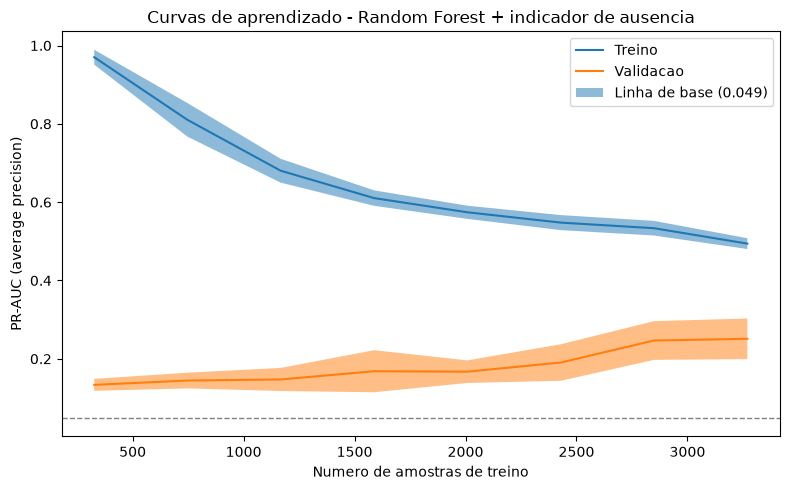

In [10]:
from sklearn.model_selection import LearningCurveDisplay

fig, ax = plt.subplots(figsize=(8, 5))

# score_type='both' plota treino e validacao juntos: a lacuna entre as
# duas curvas e o proprio diagnostico de overfitting.
LearningCurveDisplay.from_estimator(
    melhor_modelo,
    X_train,
    y_train,
    train_sizes=np.linspace(0.1, 1.0, 8),
    cv=cv,
    scoring=METRICA,
    n_jobs=-1,
    score_type="both",
    std_display_style="fill_between",
    ax=ax,
)

ax.axhline(
    y_train.mean(),
    color="gray",
    linestyle="--",
    linewidth=1,
)

ax.set_title("Curvas de aprendizado - Random Forest + indicador de ausencia")
ax.set_xlabel("Numero de amostras de treino")
ax.set_ylabel("PR-AUC (average precision)")
ax.legend(
    ["Treino", "Validacao", f"Linha de base ({y_train.mean():.3f})"],
    loc="best",
)

plt.tight_layout()
plt.show()

**Leitura.** Os valores da nossa execucao:

| Amostras de treino | PR-AUC treino | PR-AUC validacao | Lacuna |
|---:|---:|---:|---:|
| 327 | 0,970 | 0,134 | 0,837 |
| 1.167 | 0,680 | 0,147 | 0,533 |
| 2.008 | 0,574 | 0,167 | 0,407 |
| 2.849 | 0,534 | 0,247 | 0,287 |
| 3.270 | 0,494 | 0,251 | 0,243 |

Duas coisas saltam aos olhos:

**A lacuna entre treino e validacao e enorme e nunca fecha.** Com 327 amostras o
modelo tem PR-AUC de 0,970 no treino contra 0,134 na validacao - praticamente
decorou. Mesmo com todos os 3.270 exemplos a lacuna continua em 0,243. E
variancia alta, e ela persiste apesar da poda (`max_depth=5`). Com apenas 249
casos positivos no treino, cada arvore consegue isolar casos individuais.

**A curva de validacao ainda esta subindo no ultimo ponto.** De 0,134 para
0,251, e sem sinal de saturacao - o salto maior (0,191 para 0,247) acontece
justamente entre os dois ultimos pontos. Isso responde a pergunta "mais dados
ajudariam?" com um sim claro.

A conclusao pratica e que o gargalo deste trabalho nao e a escolha do algoritmo
nem o ajuste dos hiperparametros, e a quantidade de casos de AVC disponiveis.
Dobrar a base provavelmente renderia mais do que qualquer refinamento adicional
de modelagem que pudessemos fazer aqui.

---

## 2. Avaliacao do melhor modelo no conjunto de teste

Daqui em diante usamos o conjunto de teste, que nao foi tocado em nenhuma etapa
anterior - nem na exploracao da APS1, nem na selecao de hiperparametros.

In [11]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# A partir daqui usamos X_test/y_test pela primeira vez: nenhuma decisao
# de modelagem foi tomada olhando para estes dados.
melhor_modelo.fit(X_train, y_train)

y_pred = melhor_modelo.predict(X_test)
y_proba = melhor_modelo.predict_proba(X_test)[:, 1]

metricas = pd.DataFrame(
    {
        "valor": [
            accuracy_score(y_test, y_pred),
            precision_score(y_test, y_pred),
            recall_score(y_test, y_pred),
            f1_score(y_test, y_pred),
            roc_auc_score(y_test, y_proba),
            average_precision_score(y_test, y_proba),
        ]
    },
    index=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"],
).round(4)

display(metricas)

print(classification_report(y_test, y_pred, digits=3))

,valor
Accuracy,0.7319
Precision,0.1340
Recall,0.8200
F1-score,0.2303
ROC-AUC,0.8485
PR-AUC,0.2317


              precision    recall  f1-score   support

           0      0.987     0.727     0.838       972
           1      0.134     0.820     0.230        50

    accuracy                          0.732      1022
   macro avg      0.561     0.774     0.534      1022
weighted avg      0.946     0.732     0.808      1022



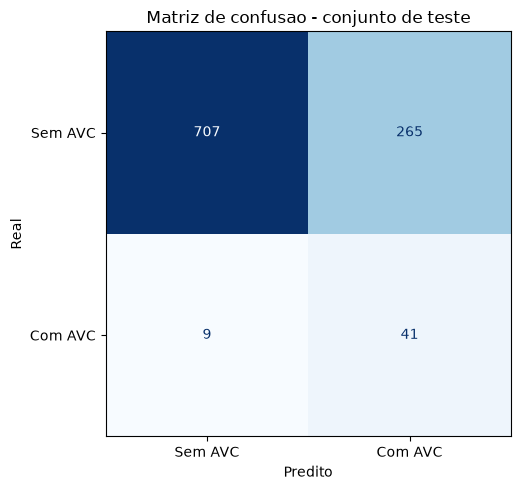

Verdadeiros negativos: 707
Falsos positivos:      265  (pacientes saudaveis sinalizados como risco)
Falsos negativos:      9  (casos de AVC que o modelo deixou passar)
Verdadeiros positivos: 41


In [12]:
fig, ax = plt.subplots(figsize=(5.5, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Sem AVC", "Com AVC"],
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

ax.set_title("Matriz de confusao - conjunto de teste")
ax.set_xlabel("Predito")
ax.set_ylabel("Real")

plt.tight_layout()
plt.show()

# ravel() desempacota a matriz 2x2 na ordem vn, fp, fn, vp, para reportar
# os quatro contadores de forma explicita.
vn, fp, fn, vp = confusion_matrix(y_test, y_pred).ravel()

print(f"Verdadeiros negativos: {vn}")
print(f"Falsos positivos:      {fp}  (pacientes saudaveis sinalizados como risco)")
print(f"Falsos negativos:      {fn}  (casos de AVC que o modelo deixou passar)")
print(f"Verdadeiros positivos: {vp}")

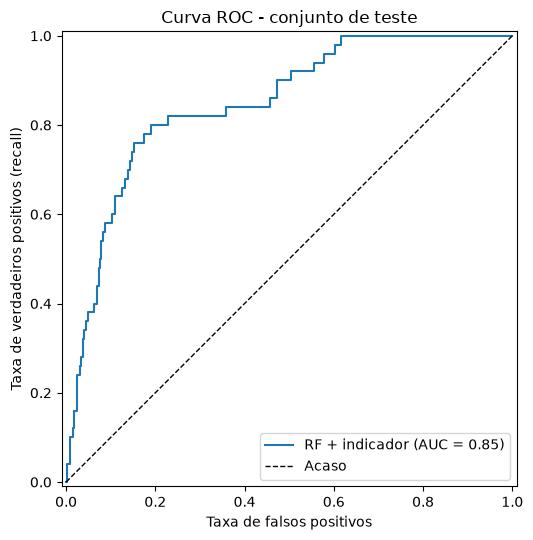

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))

RocCurveDisplay.from_predictions(y_test, y_proba, name="RF + indicador", ax=ax)

ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Acaso")

ax.set_title("Curva ROC - conjunto de teste")
ax.set_xlabel("Taxa de falsos positivos")
ax.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax.legend()

plt.tight_layout()
plt.show()

### Leitura dos resultados no teste

Os numeros da nossa execucao:

| Metrica | Valor |
|---|---:|
| Accuracy | 0,732 |
| Precision (classe AVC) | 0,134 |
| Recall (classe AVC) | 0,820 |
| F1-score (classe AVC) | 0,230 |
| ROC-AUC | 0,849 |
| PR-AUC | 0,232 |

Matriz de confusao: **41 dos 50** casos de AVC foram detectados, **9 passaram
batido**, e **265 pacientes saudaveis** foram sinalizados sem necessidade.

Tres observacoes:

**A accuracy de 0,732 e pior que a do modelo burro, e isso e bom.** Prever "sem
AVC" para todo mundo daria 0,951. Nosso modelo troca accuracy por recall de
proposito, por causa do `class_weight="balanced"`. Nesse problema e a troca
certa: um falso positivo custa um exame a mais, um falso negativo custa um
derrame nao prevenido.

**A distancia entre ROC-AUC (0,849) e PR-AUC (0,232) e a razao de termos
escolhido a PR-AUC.** Os mesmos 265 falsos positivos que destroem a precision
(0,134) mal aparecem na curva ROC, porque estao diluidos entre 972 negativos.
Reportar apenas o ROC-AUC daria a impressao de um modelo muito melhor do que ele
e.

**O limiar de 0,5 nao e obrigatorio.** Todos esses numeros vem do corte padrao.
Desloca-lo move o modelo ao longo da curva precision-recall sem retreinar nada.
A escolha do ponto deveria vir do custo relativo entre exame desnecessario e AVC
nao prevenido - uma decisao clinica, nao estatistica [7].

---

## 3. Interpretacao e explicabilidade

### 3.1 Modelo linear: os 3 coeficientes de maior magnitude

Como as variaveis numericas foram padronizadas e as categoricas estao em 0/1, os
coeficientes sao comparaveis entre si. Na regressao logistica eles estao em
escala de log-odds: um coeficiente de 1,88 significa que um desvio padrao a mais
na variavel multiplica as chances de AVC por `exp(1,88)`.

,coeficiente,odds ratio,magnitude
numericas__age,1.877,6.536,1.877
categoricas__work_type_children,0.862,2.368,0.862
binarias__hypertension,0.585,1.795,0.585


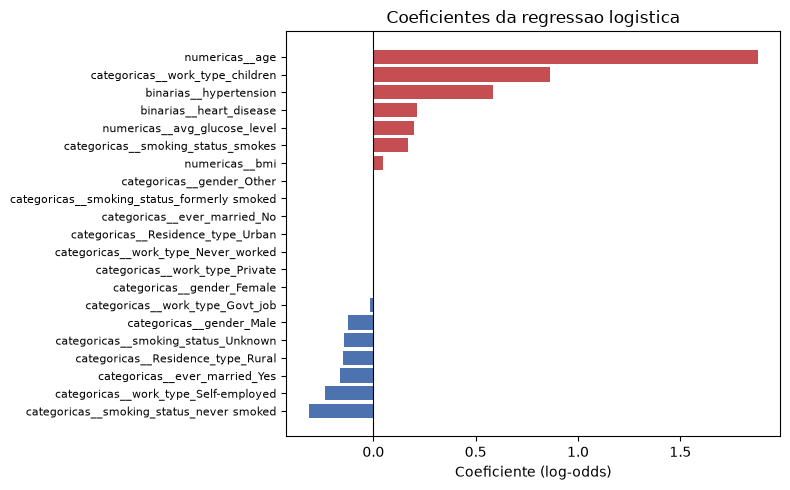

In [14]:
modelo_linear = busca_logistica.best_estimator_
modelo_linear.fit(X_train, y_train)

nomes_features = modelo_linear[:-1].get_feature_names_out()

coeficientes = pd.DataFrame(
    {
        "coeficiente": modelo_linear[-1].coef_[0],
        "odds ratio": np.exp(modelo_linear[-1].coef_[0]),
    },
    index=nomes_features,
)

# odds ratio = exp(coeficiente): leitura multiplicativa do efeito nas
# chances de AVC, mais intuitiva do que o coeficiente em log-odds.
coeficientes["magnitude"] = coeficientes["coeficiente"].abs()

display(coeficientes.sort_values("magnitude", ascending=False).head(3).round(3))

fig, ax = plt.subplots(figsize=(8, 5))

ordenados = coeficientes.sort_values("coeficiente")
cores = ["#C44E52" if c > 0 else "#4C72B0" for c in ordenados["coeficiente"]]

ax.barh(range(len(ordenados)), ordenados["coeficiente"], color=cores)
ax.set_yticks(range(len(ordenados)))
ax.set_yticklabels(ordenados.index, fontsize=8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coeficiente (log-odds)")
ax.set_title("Coeficientes da regressao logistica")

plt.tight_layout()
plt.show()

**Analise das 3 maiores magnitudes:**

**1. `age` (coeficiente +1,88, odds ratio 6,5).** Domina o modelo com folga - e
mais que o dobro do segundo colocado. Cada desvio padrao de idade (cerca de 22
anos) multiplica por 6,5 as chances de AVC. Bate com a literatura medica e com o
que a APS1 ja mostrava nos boxplots: idade e o fator de risco dominante para AVC.

**2. `work_type_children` (coeficiente +0,86).** Esse e um coeficiente que **nao
deve ser lido como causal**, e vale a pena entender por que. Criancas
praticamente nao tem AVC na base. O coeficiente positivo aparece porque o modelo
ja subtraiu uma penalidade enorme via `age` (criancas tem idade muito baixa), e
esse termo funciona como uma correcao parcial dessa penalidade. E um artefato da
colinearidade entre `work_type` e `age`, nao um achado clinico. A interpretacao
de coeficientes individuais em modelos lineares com variaveis correlacionadas
exige esse tipo de cuidado.

**3. `hypertension` (coeficiente +0,59, odds ratio 1,8).** Hipertensao quase
dobra as chances de AVC, mantidas as demais variaveis. Aqui sim temos um fator de
risco clinico bem estabelecido, e o modelo o recupera com o sinal e a ordem de
grandeza corretos.

### 3.2 Modelo ensemble: as 3 features de maior importancia

A importancia da Random Forest mede quanto cada feature contribuiu para reduzir a
impureza dos nos, somado sobre todas as arvores.

,importancia
numericas__age,0.6429
numericas__avg_glucose_level,0.1107
numericas__bmi,0.0930


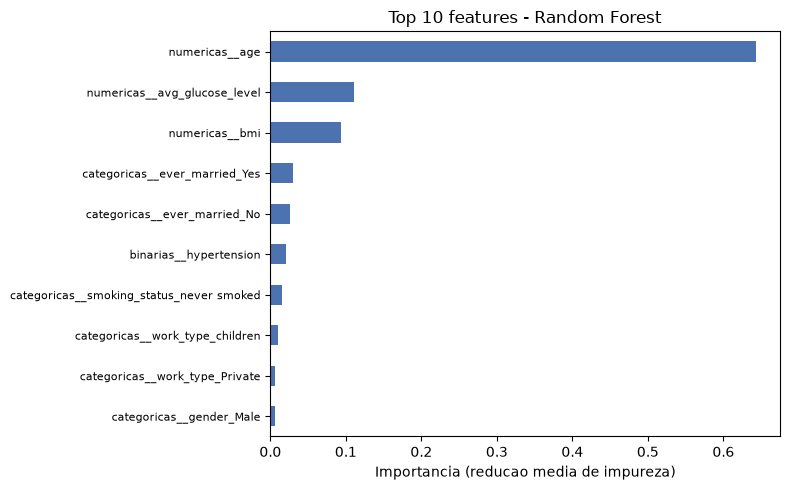

In [15]:
modelo_ensemble = busca_floresta.best_estimator_
modelo_ensemble.fit(X_train, y_train)

importancias = pd.Series(
    modelo_ensemble[-1].feature_importances_,
    index=modelo_ensemble[:-1].get_feature_names_out(),
).sort_values(ascending=False)

# feature_importances_ mede reducao media de impureza nos nos da
# floresta; nao esta na mesma escala do coeficiente da regressao
# logistica, entao os valores nao sao diretamente comparaveis entre si.
display(importancias.head(3).round(4).to_frame("importancia"))

fig, ax = plt.subplots(figsize=(8, 5))

importancias.head(10).sort_values().plot.barh(ax=ax, color="#4C72B0")

ax.set_xlabel("Importancia (reducao media de impureza)")
ax.set_title("Top 10 features - Random Forest")
ax.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()

**Analise das 3 maiores importancias:**

**1. `age` (0,643).** Sozinha responde por quase dois tercos da importancia
total. Os dois modelos, com mecanismos completamente diferentes, concordam que
idade e o preditor dominante - o que aumenta a confianca no achado.

**2. `avg_glucose_level` (0,111).** Glicose media aparece em segundo. Faz sentido
clinico (diabetes e fator de risco para AVC), mas atencao: a APS1 mostrou que
essa variavel e bimodal, com uma cauda longa de valores altos.

**3. `bmi` (0,093).** IMC em terceiro.

**Uma armadilha para registrar:** as tres features mais importantes sao
exatamente as tres variaveis **numericas continuas**. Isso nao e coincidencia. A
importancia por impureza e **enviesada a favor de variaveis com muitos valores
distintos**, porque elas oferecem mais pontos de corte possiveis e acabam sendo
escolhidas mais vezes. As variaveis binarias one-hot ficam em desvantagem
estrutural nesse calculo.

Comparando com a regressao logistica: `hypertension` aparecia la como o terceiro
coeficiente mais forte e aqui aparece com importancia de apenas 0,021. A
divergencia e sinal do vies, nao de desacordo real entre os modelos. E justamente
por isso que a proxima secao usa SHAP, que nao sofre desse problema.

### 3.3 SHAP: importancia global e explicacao de predicoes individuais

Os valores SHAP vem da teoria dos jogos cooperativos: distribuem a diferenca
entre a predicao e a media entre as features, de forma que a contribuicao de cada
uma e justa independentemente de quantos valores distintos ela assume. Resolve
exatamente o vies da secao anterior, e permite explicar **uma predicao
individual**, nao so a media [2].

Requer `uv add shap`.

In [16]:
import shap

# O explainer trabalha sobre a matriz ja pre-processada, nao sobre o DataFrame
# original, porque e isso que o classificador enxerga.
pre_ajustado = melhor_modelo[:-1]
classificador_final = melhor_modelo[-1]

X_test_proc = pre_ajustado.transform(X_test)
nomes = pre_ajustado.get_feature_names_out()

explainer = shap.TreeExplainer(classificador_final)
shap_values = explainer.shap_values(X_test_proc)

# Para classificacao binaria o retorno pode vir com a dimensao das duas classes;
# ficamos com a da classe positiva (AVC).
if isinstance(shap_values, list):
    shap_avc = shap_values[1]
elif shap_values.ndim == 3:
    shap_avc = shap_values[:, :, 1]
else:
    shap_avc = shap_values

valor_base = explainer.expected_value
if isinstance(valor_base, (list, np.ndarray)):
    valor_base = valor_base[1]

print("Formato dos valores SHAP:", shap_avc.shape)
print("Valor base (predicao media):", round(float(valor_base), 4))

Formato dos valores SHAP: (1022, 22)
Valor base (predicao media): 0.4999


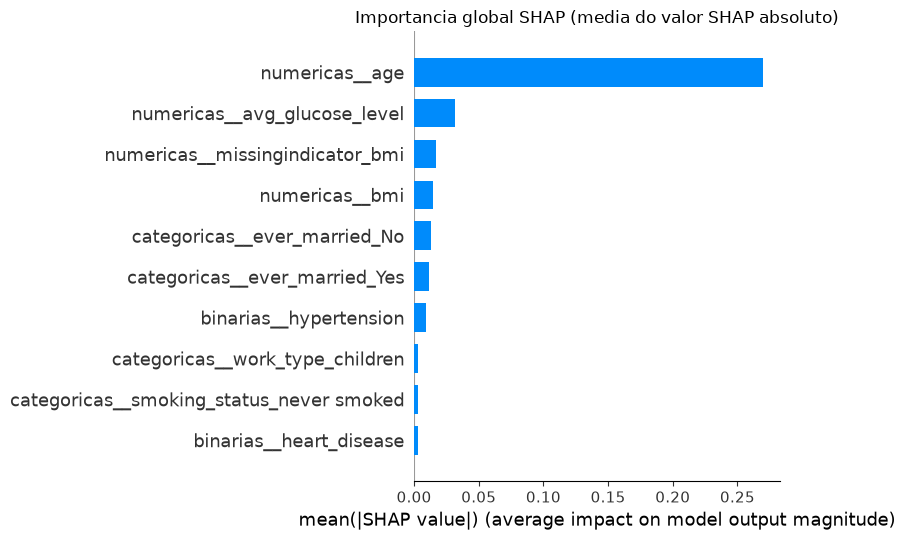

In [17]:
# plot_type='bar' resume a importancia media absoluta por feature; a
# distribuicao completa (sinal e dispersao) fica no beeswarm da celula seguinte.
shap.summary_plot(
    shap_avc,
    X_test_proc,
    feature_names=nomes,
    plot_type="bar",
    max_display=10,
    show=False,
)

plt.title("Importancia global SHAP (media do valor SHAP absoluto)")
plt.tight_layout()
plt.show()

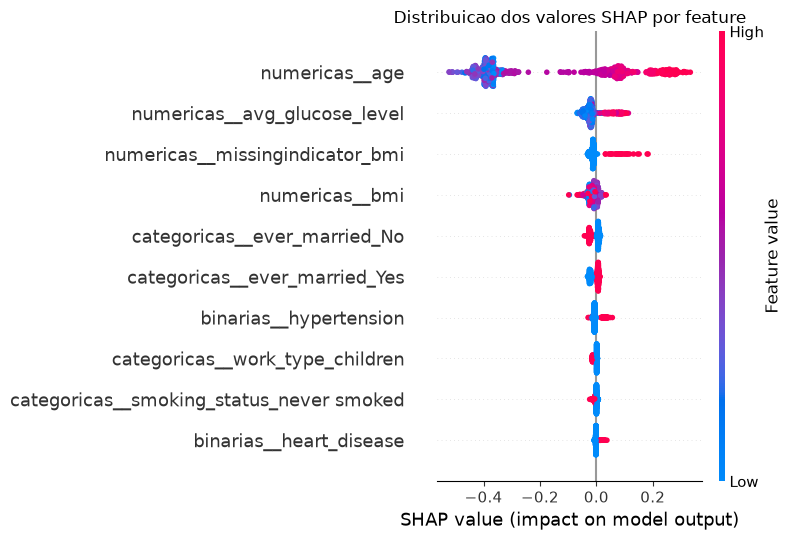

In [18]:
shap.summary_plot(
    shap_avc,
    X_test_proc,
    feature_names=nomes,
    max_display=10,
    show=False,
)

plt.title("Distribuicao dos valores SHAP por feature")
plt.tight_layout()
plt.show()

#### Importancia global: o que o SHAP corrige

| Feature | SHAP medio absoluto |
|---|---:|
| `age` | 0,2694 |
| `avg_glucose_level` | 0,0317 |
| `missingindicator_bmi` | 0,0168 |
| `bmi` | 0,0146 |
| `ever_married_No` | 0,0129 |

A concentracao em `age` fica ainda mais evidente: ela sozinha pesa **8,5 vezes**
mais que a segunda colocada.

A diferenca mais relevante em relacao a importancia por impureza da secao 3.2 e
a posicao do **`missingindicator_bmi`, que aparece em terceiro, a frente do
proprio `bmi`**. Ou seja: saber que o IMC nao foi medido vale mais, para o
modelo, do que saber o valor do IMC. A importancia por impureza nao mostrava
isso com clareza, porque penaliza variaveis binarias.

Esse e o retrato quantitativo do problema que discutimos em 1.3 e que voltara na
secao 4: o terceiro preditor mais influente do nosso melhor modelo nao e uma
caracteristica do paciente, e uma caracteristica do prontuario.

#### Explicacao de 3 predicoes individuais

Escolhemos tres pacientes que representam situacoes distintas e didaticas:

1. um **verdadeiro positivo** com a maior probabilidade predita - o caso que o
   modelo tem mais certeza;
2. um **falso negativo** - um AVC real que passou batido, onde queremos entender
   o que faltou;
3. um **falso positivo** com alta probabilidade - um alarme falso confiante.

In [19]:
y_test_array = y_test.to_numpy()

# Dentro de cada categoria de acerto/erro, pegamos o caso de maior
# confianca do modelo (maior probabilidade predita) para a explicacao.
idx_vp = np.where((y_test_array == 1) & (y_pred == 1))[0]
idx_fn = np.where((y_test_array == 1) & (y_pred == 0))[0]
idx_fp = np.where((y_test_array == 0) & (y_pred == 1))[0]

casos = {
    "Verdadeiro positivo (maior confianca)": idx_vp[np.argmax(y_proba[idx_vp])],
    "Falso negativo (AVC nao detectado)": idx_fn[np.argmax(y_proba[idx_fn])],
    "Falso positivo (alarme falso confiante)": idx_fp[np.argmax(y_proba[idx_fp])],
}

for titulo, i in casos.items():
    print("=" * 70)
    print(titulo)
    print(f"  Probabilidade predita: {y_proba[i]:.3f} | Classe real: {y_test_array[i]}")
    print()
    print("  Dados do paciente:")
    print(X_test.iloc[i].to_string())
    print()

    contribuicoes = pd.Series(shap_avc[i], index=nomes)
    principais = contribuicoes.reindex(
        contribuicoes.abs().sort_values(ascending=False).index
    ).head(3)

    print("  3 features que mais contribuiram:")
    for feature, valor in principais.items():
        direcao = "aumentou" if valor > 0 else "reduziu"
        print(f"    {feature}: {valor:+.4f} ({direcao} o risco predito)")
    print()

Verdadeiro positivo (maior confianca)
  Probabilidade predita: 0.861 | Classe real: 1

  Dados do paciente:
gender                  Male
age                     78.0
hypertension               0
heart_disease              1
ever_married             Yes
work_type            Private
Residence_type         Urban
avg_glucose_level     219.84
bmi                      NaN
smoking_status       Unknown

  3 features que mais contribuiram:
    numericas__age: +0.2261 (aumentou o risco predito)
    numericas__missingindicator_bmi: +0.0848 (aumentou o risco predito)
    numericas__avg_glucose_level: +0.0205 (aumentou o risco predito)

Falso negativo (AVC nao detectado)
  Probabilidade predita: 0.454 | Classe real: 1

  Dados do paciente:
gender                  Male
age                     59.0
hypertension               0
heart_disease              0
ever_married             Yes
work_type            Private
Residence_type         Rural
avg_glucose_level      96.16
bmi                     44.1
sm

Verdadeiro positivo (maior confianca)


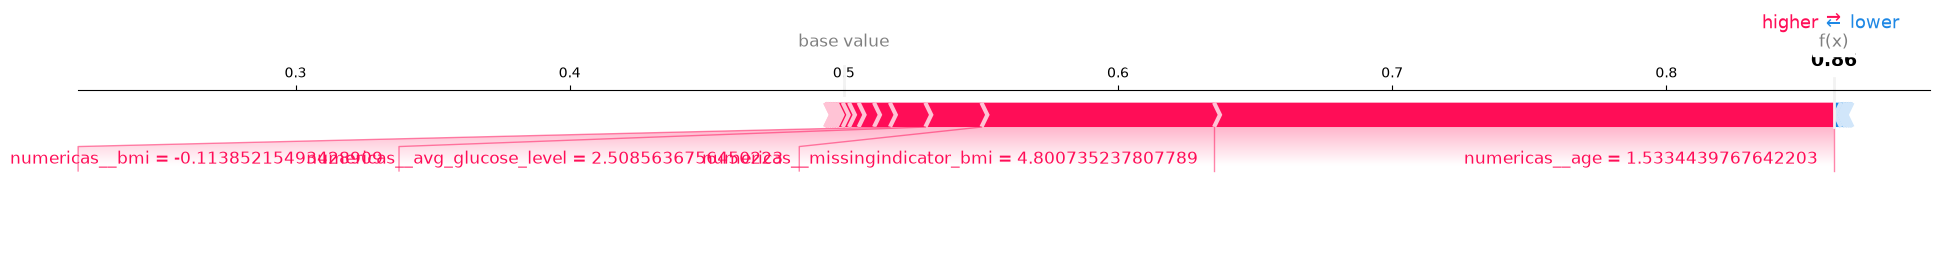

Falso negativo (AVC nao detectado)


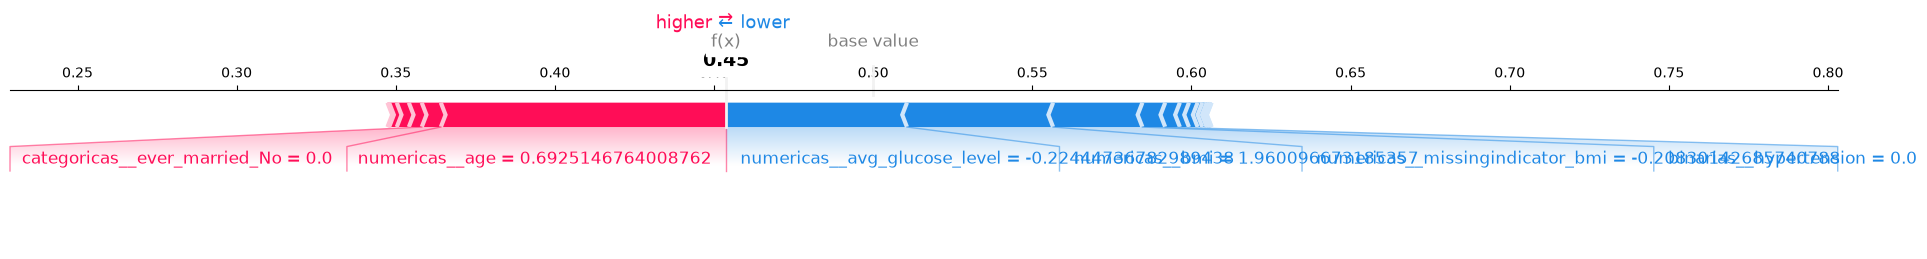

Falso positivo (alarme falso confiante)


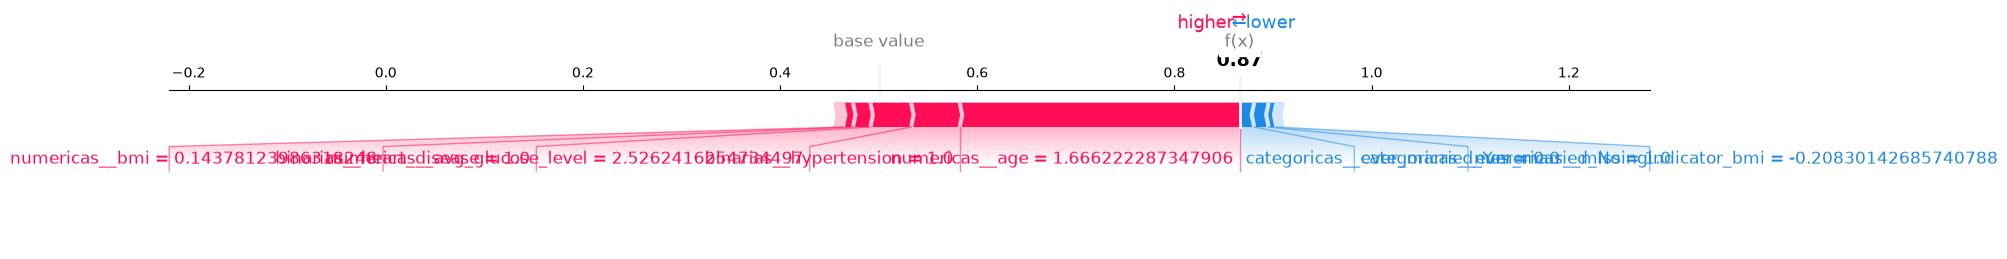

In [20]:
for titulo, i in casos.items():
    print(titulo)

    # matplotlib=True renderiza o force plot como figura estatica, o que
    # garante que ele fique salvo nos outputs do notebook exportado.
    shap.force_plot(
        valor_base,
        shap_avc[i],
        features=X_test_proc[i],
        feature_names=nomes,
        matplotlib=True,
        show=False,
    )

    plt.tight_layout()
    plt.show()

#### Analise das explicacoes individuais

**1. Verdadeiro positivo - homem, 78 anos, doenca cardiaca, glicose 219,8,
`bmi` ausente. Probabilidade predita: 0,861.**

| Feature | Contribuicao SHAP |
|---|---:|
| `age` | +0,2261 |
| `missingindicator_bmi` | +0,0848 |
| `avg_glucose_level` | +0,0205 |

Este caso e a confirmacao do problema levantado na secao 1.3. A **segunda maior
contribuicao positiva nao e um fator clinico** - e o fato de o IMC deste paciente
nao ter sido registrado. O indicador de ausencia pesa quatro vezes mais que a
glicose de 219,8 mg/dL, que e um valor altissimo, e a doenca cardiaca
diagnosticada sequer aparece no top 3.

O modelo acertou, mas em parte **pelo motivo errado**. Se este mesmo paciente
tivesse passado por um hospital que registra o IMC de todo mundo, a
probabilidade predita cairia de forma relevante - sem que nada tivesse mudado na
saude dele.

**2. Falso negativo - homem, 59 anos, sem hipertensao, sem doenca cardiaca,
glicose 96,2, IMC 44,1. Probabilidade predita: 0,454 (escapou por 0,046).**

| Feature | Contribuicao SHAP |
|---|---:|
| `age` | +0,0896 |
| `avg_glucose_level` | -0,0568 |
| `bmi` | -0,0459 |

Caso instrutivo: o modelo quase acertou, e o que o impediu foi a **ausencia de
comorbidades registradas**. A idade empurrou para cima, mas a glicose normal
(96,2) e o IMC puxaram para baixo com forca quase equivalente. Sem hipertensao e
sem doenca cardiaca no cadastro, o perfil parece de baixo risco.

Chama atencao que o IMC de 44,1 - obesidade grave - tenha **reduzido** o risco
predito. Isso contraria o senso clinico e indica que o modelo nao aprendeu uma
relacao confiavel para `bmi`, provavelmente porque a cauda alta da distribuicao
tem poucos exemplos com AVC.

**3. Falso positivo - homem, 81 anos, hipertensao, doenca cardiaca, glicose
220,6, IMC 30,0. Probabilidade predita: 0,866.**

| Feature | Contribuicao SHAP |
|---|---:|
| `age` | +0,2839 |
| `hypertension` | +0,0493 |
| `avg_glucose_level` | +0,0413 |

Aqui o modelo **nao errou de forma absurda**. Ele identificou um paciente de 81
anos que acumula hipertensao, doenca cardiaca e glicose de 220,6 - um perfil de
risco real, pelos tres fatores classicos e na ordem clinicamente esperada. O AVC
simplesmente nao aconteceu.

Para uma ferramenta de triagem esse tipo de erro e aceitavel: encaminhar esse
paciente a um cardiologista seria uma decisao defensavel mesmo sabendo o
desfecho. E uma diferenca qualitativa importante em relacao ao falso negativo do
caso 2, que seria um erro com custo clinico real.

**Comparando os tres.** `age` e a maior contribuicao nos tres casos, e nos dois
de alta confianca ela e 3 a 6 vezes maior que a segunda colocada. O SHAP
individual torna concreto o que as metricas globais ja sugeriam: o modelo decide
principalmente pela idade, e os demais fatores apenas ajustam a margem.

---

## 4. Discussao critica

### 4.1 Duas limitacoes do melhor modelo

**(1) O modelo depende de um artefato de coleta, nao de um fator clinico.**

O maior ganho de desempenho de todo o trabalho (+21% de PR-AUC) veio do indicador
de ausencia do `bmi`. Mas "o IMC nao foi registrado" nao e um fator de risco - e
um sintoma de como estes dados especificos foram coletados, provavelmente ligado
a pacientes graves ou que vieram a obito. Em um hospital diferente, com outro
protocolo de registro, essa coluna significaria outra coisa ou nada. **O modelo
aprendeu algo que nao transfere.** Pior: se o hospital melhorar o preenchimento
do cadastro, o desempenho do modelo cai, sem que nada tenha mudado nos pacientes.
E uma dependencia fragil e invisivel em producao. Esse e um exemplo do fenomeno de *dataset shift* bem documentado na literatura de IA clinica [3].

**(2) Na pratica, o modelo e em grande parte um detector de idade.**

`age` responde por 64% da importancia da floresta e tem coeficiente mais que duas
vezes maior que o segundo na regressao logistica. Isso levanta a questao de qual
e o ganho real sobre uma regra simples do tipo "encaminhe todo paciente acima de
60 anos". O modelo acerta nos casos faceis (idosos de alto risco) e erra
justamente nos dificeis - os pacientes jovens com AVC, que sao os que mais se
beneficiariam de uma triagem automatizada, ja que o medico dificilmente
suspeitaria deles. Ou seja, **o valor clinico esta concentrado exatamente onde o
modelo e mais fraco.** Essa concentracao de importancia em idade e consistente com a epidemiologia do AVC, em que a idade e sistematicamente apontada como o fator de risco de maior peso populacional [4].

### 4.2 Duas limitacoes dos dados

**(1) O dataset nao tem dimensao temporal.**

Cada linha e uma fotografia: as features e o `stroke` estao no mesmo instante.
Nao sabemos se a hipertensao foi diagnosticada antes ou depois do AVC, nem se a
glicose foi medida na internacao causada pelo proprio AVC. Isso inviabiliza
qualquer afirmacao causal e, mais grave, abre espaco para **vazamento temporal**:
parte do que o modelo usa como "preditor" pode ser consequencia do desfecho. Um
modelo de predicao de risco precisaria de features medidas comprovadamente
*antes* do evento. Esse risco - um preditor que na verdade carrega informacao do proprio desfecho - e descrito em detalhe na literatura de deteccao de vazamento de dados [5].

**(2) Nao sabemos de onde vem a amostra, e a prevalencia nao e plausivel.**

A base nao documenta hospital, pais, periodo ou criterio de inclusao. A
prevalencia de 4,87% e muito superior a prevalencia populacional de AVC, o que
indica alguma forma de selecao da amostra. Sem saber qual, nao e possivel saber a
que populacao o modelo se aplica, e as probabilidades que ele produz estao
descalibradas para qualquer populacao real. Alem disso, a coluna `gender` tem uma
unica ocorrencia da categoria "Other", o que torna o modelo completamente inutil
para esse grupo e e um problema de representatividade que nenhuma tecnica de
modelagem resolve. A prevalencia populacional de AVC reportada na literatura epidemiologica fica tipicamente na faixa de 1-2% em estudos transversais [4], o que reforca a suspeita de selecao na amostra.

### 4.3 Duas acoes para operacionalizacao e manutencao

**(1) Monitorar a distribuicao das entradas, nao so o desempenho.**

O desfecho de AVC leva meses ou anos para ser observado, entao esperar pelos
rotulos para descobrir que o modelo degradou significa descobrir tarde demais. A
acao concreta e registrar, a cada lote de predicoes, a distribuicao das features
de entrada e comparar com a do treino - com atencao especial a **taxa de ausencia
do `bmi`**, pela dependencia descrita em 4.1. Um alarme automatico quando essa
taxa sair da faixa observada no treino (3,93%) detectaria o problema
imediatamente, sem precisar de um unico rotulo novo. Monitorar a distribuicao de entrada, e nao so a metrica de desempenho, e uma recomendacao central tanto na literatura de dataset shift em saude [3] quanto na de manutencao de sistemas de ML em producao [6].

**(2) Separar a escolha do limiar do treinamento do modelo, e revisa-la
periodicamente.**

Hoje usamos o limiar padrao de 0,5, que nao tem nenhuma justificativa clinica. O
limiar deveria ser um parametro de configuracao definido pela equipe medica a
partir da capacidade de atendimento disponivel: quantos encaminhamentos por mes o
servico comporta define diretamente onde cortar na curva precision-recall. Mantido
fora do modelo, esse valor pode ser recalibrado quando a capacidade mudar, sem
retreinar nada. Combinado com uma revisao periodica (semestral) com dados novos
rotulados, isso mantem o sistema util sem exigir uma reimplantacao completa a
cada ajuste. Essa separacao entre o modelo, que estima probabilidades, e o limiar de decisao, que reflete custos e capacidade operacional, segue o principio de analise custo-sensivel discutido na literatura de ciencia de dados aplicada [7].

---

## 5. Referencias bibliograficas

[1] RUBIN, D. B. Inference and Missing Data. *Biometrika*, v. 63, n. 3, p. 581-592, 1976.

[2] LUNDBERG, S. M.; LEE, S.-I. A Unified Approach to Interpreting Model Predictions. In: *Advances in Neural Information Processing Systems (NeurIPS)*, v. 30, 2017.

[3] FINLAYSON, S. G. et al. The Clinician and Dataset Shift in Artificial Intelligence. *New England Journal of Medicine*, v. 385, n. 3, p. 283-286, 2021.

[4] GBD 2019 STROKE COLLABORATORS. Global, Regional, and National Burden of Stroke and Its Risk Factors, 1990-2019: A Systematic Analysis for the Global Burden of Disease Study 2019. *The Lancet Neurology*, v. 20, n. 10, p. 795-820, 2021.

[5] KAUFMAN, S.; ROSSET, S.; PERLICH, C. Leakage in Data Mining: Formulation, Detection, and Avoidance. *ACM Transactions on Knowledge Discovery from Data*, v. 6, n. 4, p. 1-21, 2012.

[6] SCULLEY, D. et al. Hidden Technical Debt in Machine Learning Systems. In: *Advances in Neural Information Processing Systems (NeurIPS)*, v. 28, 2015.

[7] PROVOST, F.; FAWCETT, T. *Data Science for Business*. Sebastopol: O'Reilly Media, 2013.